# Case 2: The cost threshold: what does Anand's 1-in-31 rule do to the bank's calls?

*Applies chapters 4 and 5: choosing the metric from business cost and the 1-in-N test; threshold selection as a business decision. Also searched as: cost-sensitive evaluation, classification threshold tuning, expected cost.*

**Who needs the answer.** Anand Iyer, Finance controller at Kalpa Retail, who prices a wasted nudge at Rs 40 and a missed buyer at about Rs 1,200, and the Marketing team who must say whom to call. The business owner's question is the bill: what does each threshold cost in rupees?

**The questions on the way.** Where does the 1-in-31 rule put the threshold on the bank's scores? How many clients does it call? How much cheaper is it than the rules that need no model at all? At what cost ratio does the model start to matter?

Case 1 ended with Monday's model at 0.5: 174 of 928 buyers found. This case adds one decision, the threshold, priced with Kalpa's costs on the bank's calls.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

# Load the day's public dataset once; later runs read the cached copy.
# UCI Bank Marketing, bank-additional-full.csv, CC BY 4.0 (Moro, Rita and Cortez, 2014).
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call (Monday's columns): who the client is, how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, Friday's envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

bank = load_bank()
train, val, test = week_split(bank)
model = logistic(COLS, bank).fit(train[COLS], (train["y"] == "yes").astype(int))
y_val = (val["y"] == "yes").astype(int).to_numpy()      # 1 = the client subscribed (a buyer)
p_val = model.predict_proba(val[COLS])[:, 1]             # the model's P(buy) for each validation client
print(f"rows {len(bank):,}; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed until Friday)")
print(f"buyers in validation: {y_val.sum():,} of {len(y_val):,}, a base rate of {y_val.mean():.2%}")

def cells(y, p, threshold):
    """The four boxes at one threshold: act (call, nudge) when the score is at or above it."""
    act = p >= threshold
    tp = int((act & (y == 1)).sum()); fp = int((act & (y == 0)).sum())
    fn = int((~act & (y == 1)).sum()); tn = int((~act & (y == 0)).sum())
    return tp, fp, fn, tn

rows 41,188; train 24,712, validation 8,238, test 8,238 (sealed until Friday)
buyers in validation: 928 of 8,238, a base rate of 11.26%


In [2]:
tp, fp, fn, tn = cells(y_val, p_val, 0.5)
print(f"Case 1's state at 0.5: TP {tp}, FP {fp}, FN {fn}, TN {tn:,}")
print("PASS  the starting matrix matches case 1" if (tp, fp, fn, tn) == (174, 94, 754, 7216) else "CHECK the starting state moved")
COST_FP, COST_FN = 40, 1200                      # Anand's prices: a wasted nudge, a missed buyer
def bill(tp, fp, fn, tn):
    return fp * COST_FP + fn * COST_FN
print(f"the bill at 0.5: {fp:,} wasted x Rs 40 + {fn:,} missed x Rs 1,200 = Rs {bill(tp, fp, fn, tn):,}")

Case 1's state at 0.5: TP 174, FP 94, FN 754, TN 7,216
PASS  the starting matrix matches case 1
the bill at 0.5: 94 wasted x Rs 40 + 754 missed x Rs 1,200 = Rs 908,560


## The options: which threshold should the team ship?

Four ways a team could set it. Each is sized below in calls, buyers found and the rupee bill of mistakes on these 8,238 clients.

1. **Keep 0.5**, the library default.
2. **The F1 threshold**, the one that maximises F1, because F1 "balances" the two errors.
3. **The cost threshold** from the 1-in-N test: thirty Rs 40 nudges are paid for by one Rs 1,200 buyer, so act when P(buy) is above 1 in 31, `40 / (40 + 1,200) = 0.032`.
4. **Call everyone**, the rule that needs no model.

**Predict before you run.** Which option has the lowest bill? (a) 0.5, (b) the F1 threshold, (c) the cost threshold, (d) call everyone.

In [3]:
grid = np.round(np.arange(0.001, 1.0, 0.001), 3)
f1s = []
for t in grid:
    a, b, c, d = cells(y_val, p_val, t)
    f1s.append(2 * a / (2 * a + b + c) if a else 0)
t_f1 = grid[int(np.argmax(f1s))]
t_cost = COST_FP / (COST_FP + COST_FN)
options = {"keep 0.5": 0.5, f"F1 threshold ({t_f1:.3f})": t_f1, f"cost threshold ({t_cost:.3f})": t_cost, "call everyone": 0.0}
rows = []
for name, t in options.items():
    a, b, c, d = cells(y_val, p_val, t)
    rows.append([name, a + b, a, b, c, bill(a, b, c, d)])
sizing = pd.DataFrame(rows, columns=["option", "called", "buyers found", "wasted", "missed", "bill Rs"])
print(sizing.to_string(index=False, formatters={"called": "{:,}".format, "wasted": "{:,}".format, "bill Rs": "{:,}".format}))

                option called  buyers found wasted  missed bill Rs
              keep 0.5    268           174     94     754 908,560
  F1 threshold (0.154)  1,226           454    772     474 599,680
cost threshold (0.032)  7,438           913  6,525      15 279,000
         call everyone  8,238           928  7,310       0 292,400


**What happened.** The answer is (c). The cost threshold calls 7,438 clients, about nine in ten, finds 913 of 928 buyers, and leaves the lowest bill, Rs 2.79 lakh. The F1 threshold sits far higher because F1 counts a wasted call and a missed buyer as equally bad, when Anand prices one at thirty times the other. The call: ship the cost threshold. The fact that would change it is the price ratio, and the next sections show how much.

## How does the bill move as the threshold slides?

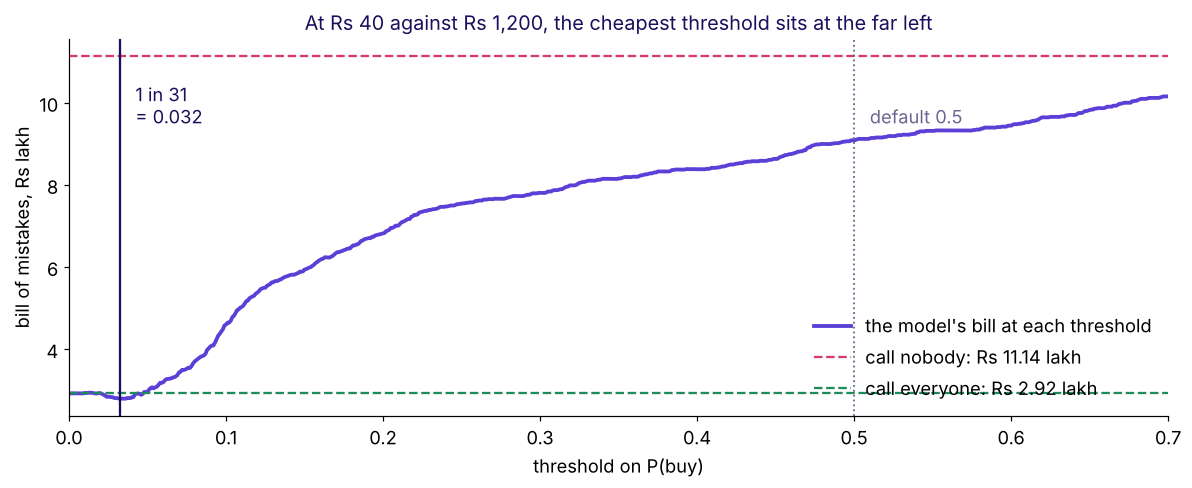

lowest bill on the grid: Rs 279,320 at threshold 0.033


In [4]:
bills = np.array([bill(*cells(y_val, p_val, t)) for t in grid])
nobody = y_val.sum() * COST_FN
everyone = (len(y_val) - y_val.sum()) * COST_FP
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(grid, bills / 1e5, color=VIOLET, lw=2.5, label="the model's bill at each threshold")
ax.axhline(nobody / 1e5, color=ROSE, ls="--", label=f"call nobody: Rs {nobody / 1e5:.2f} lakh")
ax.axhline(everyone / 1e5, color=GREEN, ls="--", label=f"call everyone: Rs {everyone / 1e5:.2f} lakh")
ax.axvline(t_cost, color=INK, lw=1.5); ax.text(t_cost + 0.01, 9.5, "1 in 31\n= 0.032", color=INK)
ax.axvline(0.5, color=MUTED, lw=1.2, ls=":"); ax.text(0.51, 9.5, "default 0.5", color=MUTED)
ax.set_xlabel("threshold on P(buy)"); ax.set_ylabel("bill of mistakes, Rs lakh"); ax.set_xlim(0, 0.7)
ax.set_title("At Rs 40 against Rs 1,200, the cheapest threshold sits at the far left", color=INK)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
print(f"lowest bill on the grid: Rs {bills.min():,} at threshold {grid[bills.argmin()]:.3f}")

## The trap: how much does the model really save?

A hurried analyst compares the cost threshold with the default and writes: **"Setting the threshold from costs saves Rs 6.3 lakh."** The arithmetic is right and the comparison is wrong, because nobody would ship 0.5 once the costs are on the table. The honest comparison is with the best rule that needs no model, which here is calling everyone. If Kalpa funded a model build on the Rs 6.3 lakh, it would be paying for a saving a spreadsheet rule already gets. The check is to always price the free rules; the fix is to report the saving against the cheaper of call-nobody and call-everyone.

In [5]:
b_cost = bill(*cells(y_val, p_val, t_cost)); b_half = bill(*cells(y_val, p_val, 0.5))
best_free = min(nobody, everyone)
at_stake = y_val.sum() * COST_FN                  # all the buyer margin there is in this slice
print(f"saving against 0.5:            Rs {b_half - b_cost:,}   (the misleading number)")
print(f"saving against calling everyone: Rs {best_free - b_cost:,}")
print(f"  that is {(best_free - b_cost) / best_free:.1%} of the free rule's bill")
print(f"  and {(best_free - b_cost) / at_stake:.1%} of the Rs {at_stake:,} buyer margin at stake")
print("PASS  the cost threshold is 1 in 31" if abs(t_cost - 1 / 31) < 1e-12 else "CHECK threshold")
print("PASS  the model beats the best free rule, by under 5 percent of its bill" if 0 < (best_free - b_cost) / best_free < 0.05 else "CHECK saving")

saving against 0.5:            Rs 629,560   (the misleading number)
saving against calling everyone: Rs 13,400
  that is 4.6% of the free rule's bill
  and 1.2% of the Rs 1,113,600 buyer margin at stake
PASS  the cost threshold is 1 in 31
PASS  the model beats the best free rule, by under 5 percent of its bill


## When does the model start to matter?

Keep the Rs 40 nudge and lower the price of a missed buyer, so the ratio tightens from 30 to 1 down to 2 to 1. At each ratio the threshold is re-derived from the 1-in-N test and the model's bill is compared with the cheaper free rule.

**Predict before you run.** As the ratio tightens from 30 to 1 towards 5 to 1, does the model's saving over the free rules (a) shrink, (b) stay flat, (c) grow?

miss : waste  threshold called model bill Rs best free rule Rs saving
        30:1      0.032  7,438       279,000           292,400   4.6%
        20:1      0.048  6,149       268,480           292,400   8.2%
        15:1      0.062  5,233       251,560           292,400  14.0%
        10:1      0.091  3,459       210,360           292,400  28.1%
         8:1      0.111  2,096       180,640           292,400  38.2%
         5:1      0.167  1,123       127,080           185,600  31.5%
         3:1      0.250    624        86,720           111,360  22.1%
         2:1      0.333    478        62,160            74,240  16.3%


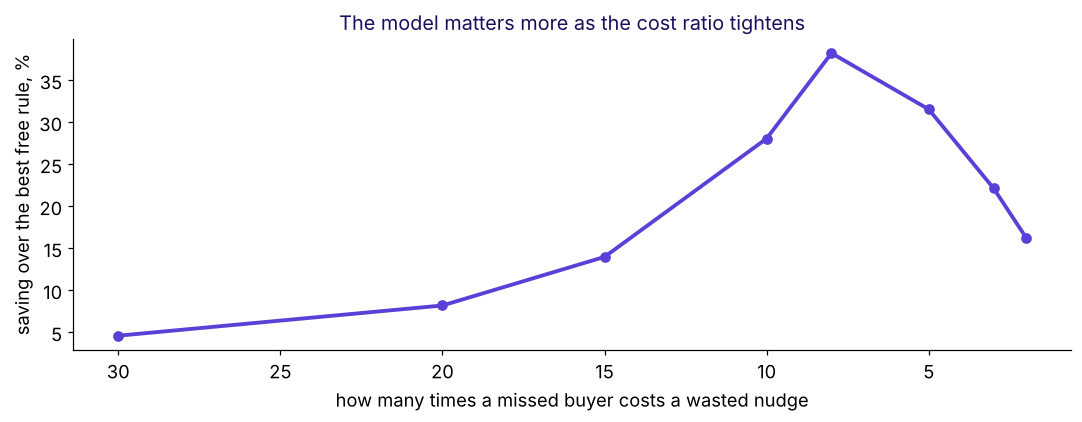

In [6]:
ratios = [30, 20, 15, 10, 8, 5, 3, 2]
out = []
for r in ratios:
    c_fn = COST_FP * r
    t = COST_FP / (COST_FP + c_fn)
    a, b, c, d = cells(y_val, p_val, t)
    model_bill = b * COST_FP + c * c_fn
    free = min(y_val.sum() * c_fn, (len(y_val) - y_val.sum()) * COST_FP)
    out.append([f"{r}:1", round(t, 3), a + b, model_bill, free, (free - model_bill) / free])
sweep = pd.DataFrame(out, columns=["miss : waste", "threshold", "called", "model bill Rs", "best free rule Rs", "saving"])
print(sweep.to_string(index=False, formatters={"called": "{:,}".format, "model bill Rs": "{:,}".format,
                                                "best free rule Rs": "{:,}".format, "saving": "{:.1%}".format}))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ratios, sweep["saving"] * 100, "o-", color=VIOLET, lw=2.5)
ax.set_xlabel("how many times a missed buyer costs a wasted nudge"); ax.set_ylabel("saving over the best free rule, %")
ax.invert_xaxis(); ax.set_title("The model matters more as the cost ratio tightens", color=INK)
plt.tight_layout(); plt.show()

**What happened.** The answer is (c) at first: the saving grows from under 5 percent at 30 to 1 to almost 40 percent at 8 to 1, then falls again as calling nobody becomes the cheap free rule. At Anand's 30 to 1 a call is so cheap against a buyer that calling nearly everyone is close to optimal, and the model barely matters. That is the flip condition of the cost rule: the model earns its keep when the ratio tightens, or when something else limits how many calls can be made, which is case 3.

In [7]:
s30 = sweep.loc[sweep["miss : waste"] == "30:1", "saving"].item(); s10 = sweep.loc[sweep["miss : waste"] == "10:1", "saving"].item()
print("PASS  at 30:1 the saving is under 5 percent" if s30 < 0.05 else "CHECK 30:1")
print("PASS  at 10:1 the saving is above 20 percent" if s10 > 0.20 else "CHECK 10:1")

PASS  at 30:1 the saving is under 5 percent
PASS  at 10:1 the saving is above 20 percent


## A second route: does the expected-value rule pick the same clients?

The 1-in-N test can be written per client: nudge when the expected margin of the nudge beats its price, `P(buy) x 1,200 > (1 - P(buy)) x 40`. Rearranged, that is exactly `P(buy) > 40 / 1,240`. The cell below applies the per-client form and checks it calls the same clients.

In [8]:
ev_rule = p_val * COST_FN > (1 - p_val) * COST_FP
threshold_rule = p_val > t_cost
print(f"clients called by the expected-value rule: {ev_rule.sum():,}; by the threshold: {threshold_rule.sum():,}")
print("PASS  both routes call the same clients" if (ev_rule == threshold_rule).all() else "CHECK the routes differ")

clients called by the expected-value rule: 7,438; by the threshold: 7,438
PASS  both routes call the same clients


## What did this case establish, and what comes next?

| Question | Answer from this run |
|---|---|
| Where does 1 in 31 put the threshold? | 0.032, calling 7,438 of 8,238 clients and finding 913 of 928 buyers |
| How much cheaper than the free rules? | Rs 2,79,000 against Rs 2,92,400 for calling everyone: Rs 13,400, under 5 percent of the bill and about 1.2 percent of the buyer margin at stake |
| When does the model matter? | When the ratio tightens (about 39 percent saving at 8 to 1) or when a budget limits the calls |

**In the interview.** "How do you set a threshold when the two errors cost differently?" Derive it from the costs, then say what the free rules cost and when the model stops mattering.

Case 3 puts a budget on the calls: Marketing can afford 1,000 in this slice.